Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
Training samples: 12954
Epoch [1/5] | Loss D: 0.0055 | Loss G: 5.8873
Epoch [2/5] | Loss D: 0.0014 | Loss G: 7.2103
Epoch [3/5] | Loss D: 0.0006 | Loss G: 8.0484
Epoch [4/5] | Loss D: 0.0003 | Loss G: 8.8536
Epoch [5/5] | Loss D: 0.0002 | Loss G: 9.1901
Testing samples: 1176851

GAN ANOMALY DETECTION RESULTS
Accuracy:  0.4116
Precision: 0.9952
Recall:    0.3993
F1 Score:  0.5699

Predicted benign: 715787
Predicted anomalies: 461064

Classification Report:
              precision    recall  f1-score   support

      Benign       0.04      0.92      0.07     27709
     Anomaly       1.00      0.40      0.57   1149142

    accuracy                           0.41   1176851
   macro avg       0.52      0.66      0.32   1176851
weighted avg       0.97      0.41      0.56   1176851



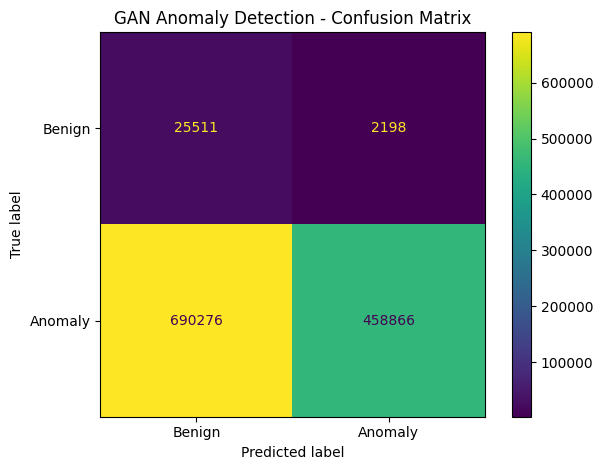

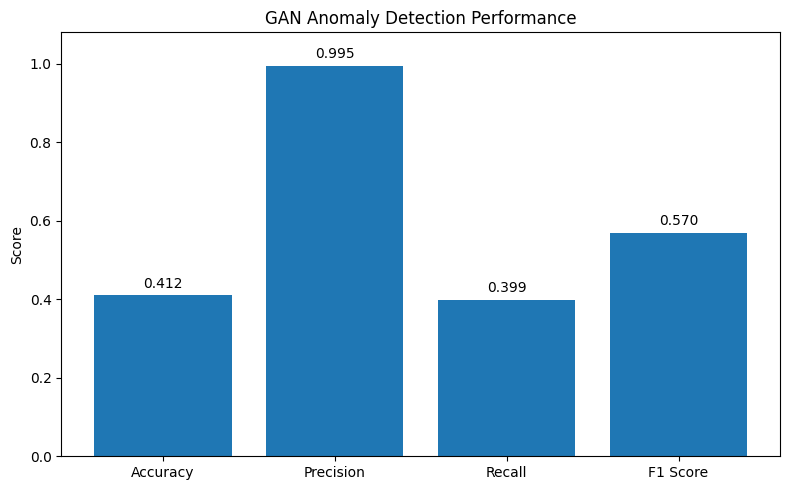

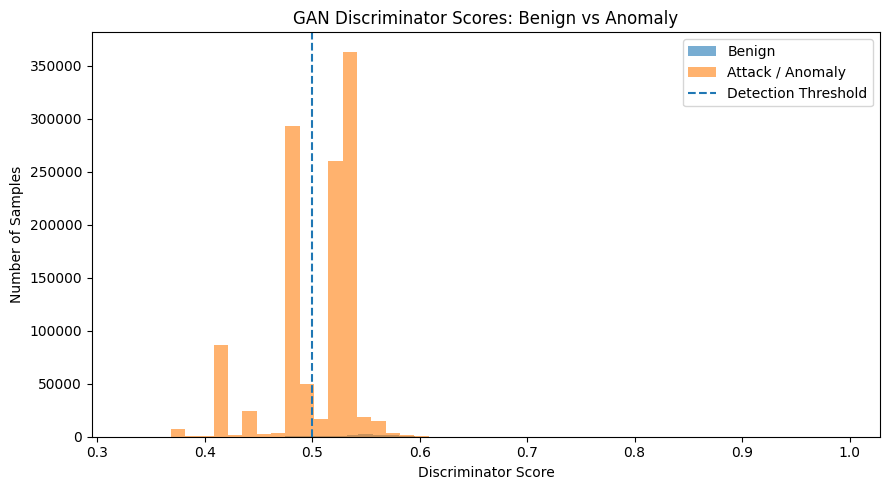

In [3]:
# ============================================================
# THEIA GAN - TRAINING, TESTING AND EVALUATION
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    ConfusionMatrixDisplay
)


# ============================================================
# FILES AND DEVICE
# ============================================================

TRAIN_CSV = "/content/drive/MyDrive/Theia_Data/train.csv"
TEST_CSV = "/content/drive/MyDrive/Theia_Data/test.csv"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# LOAD DATA
# ============================================================

# Load test data once
test_df = pd.read_csv(TEST_CSV)

# Check whether train.csv already has headers
train_columns = pd.read_csv(
    TRAIN_CSV,
    nrows=0
).columns

if "label" in train_columns:
    train_df = pd.read_csv(TRAIN_CSV)
else:
    train_df = pd.read_csv(
        TRAIN_CSV,
        header=None,
        names=test_df.columns
    )


# ============================================================
# PREPARE TRAINING DATA
# ============================================================

# Train GAN only on benign traffic
train_df = train_df[
    train_df["label"] == "BenignTraffic"
].drop(columns="label")

# Use 10% of benign traffic and cap at 50,000 samples
train_df = train_df.sample(
    frac=0.10,
    random_state=42
).head(50000)

# Keep numeric data and clean invalid values
train_df = train_df.select_dtypes(
    include=[np.number]
).replace(
    [np.inf, -np.inf],
    np.nan
)

feature_columns = train_df.columns
medians = train_df.median()

train_df = train_df.fillna(medians)

# Save training scaling values
data_min = train_df.min()
data_max = train_df.max()

data_range = (
    data_max - data_min
).replace(0, 1)


# Convert network data into 16 x 16 GAN input
def to_gan_tensor(df):

    scaled = (
        2 * (df - data_min) / data_range - 1
    ).to_numpy(dtype=np.float32)

    padded = np.pad(
        scaled,
        (
            (0, 0),
            (0, 256 - scaled.shape[1])
        )
    )

    return torch.from_numpy(
        padded.reshape(-1, 1, 16, 16)
    )


train_tensor = to_gan_tensor(train_df)

train_loader = DataLoader(
    train_tensor,
    batch_size=128,
    shuffle=True,
    num_workers=2
)

print("Training samples:", len(train_tensor))


# ============================================================
# GAN
# ============================================================

Z_DIM = 100

generator = nn.Sequential(

    nn.ConvTranspose2d(
        Z_DIM, 256, 4, 1, 0
    ),

    nn.BatchNorm2d(256),
    nn.ReLU(True),

    nn.ConvTranspose2d(
        256, 128, 4, 2, 1
    ),

    nn.BatchNorm2d(128),
    nn.ReLU(True),

    nn.ConvTranspose2d(
        128, 1, 4, 2, 1
    ),

    nn.Tanh()

).to(device)


discriminator = nn.Sequential(

    nn.Conv2d(
        1, 128, 4, 2, 1
    ),

    nn.LeakyReLU(
        0.2,
        inplace=True
    ),

    nn.Conv2d(
        128, 256, 4, 2, 1
    ),

    nn.BatchNorm2d(256),

    nn.LeakyReLU(
        0.2,
        inplace=True
    ),

    nn.Conv2d(
        256, 1, 4, 1, 0
    ),

    nn.Sigmoid()

).to(device)


criterion = nn.BCELoss()

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)


# ============================================================
# TRAIN GAN
# ============================================================

for epoch in range(5):

    for real in train_loader:

        real = real.to(device)
        batch_size = real.size(0)

        # Train discriminator
        optimizer_D.zero_grad()

        real_output = discriminator(real)

        loss_real = criterion(
            real_output,
            torch.ones_like(real_output)
        )

        noise = torch.randn(
            batch_size,
            Z_DIM,
            1,
            1,
            device=device
        )

        fake = generator(noise)

        fake_output = discriminator(
            fake.detach()
        )

        loss_fake = criterion(
            fake_output,
            torch.zeros_like(fake_output)
        )

        loss_D = loss_real + loss_fake

        loss_D.backward()
        optimizer_D.step()


        # Train generator
        optimizer_G.zero_grad()

        generator_output = discriminator(fake)

        loss_G = criterion(
            generator_output,
            torch.ones_like(generator_output)
        )

        loss_G.backward()
        optimizer_G.step()


    print(
        f"Epoch [{epoch + 1}/5] | "
        f"Loss D: {loss_D.item():.4f} | "
        f"Loss G: {loss_G.item():.4f}"
    )


# ============================================================
# PREPARE TEST DATA
# ============================================================

# 0 = Benign
# 1 = Attack / Anomaly

true_labels = (
    test_df["label"] != "BenignTraffic"
).astype(int).to_numpy()


test_features = (

    test_df
    .reindex(columns=feature_columns)

    .replace(
        [np.inf, -np.inf],
        np.nan
    )

    .fillna(medians)
)


test_tensor = to_gan_tensor(
    test_features
)

test_loader = DataLoader(
    test_tensor,
    batch_size=4096,
    shuffle=False
)

print("Testing samples:", len(test_tensor))


# ============================================================
# GAN EVALUATION
# ============================================================

discriminator.eval()

scores = []

with torch.no_grad():

    for batch in test_loader:

        output = discriminator(
            batch.to(device)
        )

        scores.extend(
            output
            .flatten()
            .cpu()
            .numpy()
        )


scores = np.array(scores)

threshold = 0.5

predicted_labels = (
    scores < threshold
).astype(int)


# ============================================================
# RESULTS
# ============================================================

accuracy = accuracy_score(
    true_labels,
    predicted_labels
)

precision, recall, f1, _ = (
    precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        average="binary",
        zero_division=0
    )
)


print("\nGAN ANOMALY DETECTION RESULTS")

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

print(
    "\nPredicted benign:",
    np.sum(predicted_labels == 0)
)

print(
    "Predicted anomalies:",
    np.sum(predicted_labels == 1)
)


print("\nClassification Report:")

print(
    classification_report(
        true_labels,
        predicted_labels,
        target_names=[
            "Benign",
            "Anomaly"
        ],
        zero_division=0
    )
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

ConfusionMatrixDisplay.from_predictions(
    true_labels,
    predicted_labels,
    display_labels=[
        "Benign",
        "Anomaly"
    ]
)

plt.title(
    "GAN Anomaly Detection - Confusion Matrix"
)

plt.tight_layout()
plt.show()


# ============================================================
# PERFORMANCE GRAPH
# ============================================================

metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
}

plt.figure(
    figsize=(8, 5)
)

bars = plt.bar(
    metrics.keys(),
    metrics.values()
)

plt.bar_label(
    bars,
    fmt="%.3f",
    padding=3
)

plt.ylim(
    0,
    1.08
)

plt.ylabel("Score")

plt.title(
    "GAN Anomaly Detection Performance"
)

plt.tight_layout()
plt.show()


# ============================================================
# DISCRIMINATOR SCORE GRAPH
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.hist(
    scores[true_labels == 0],
    bins=50,
    alpha=0.6,
    label="Benign"
)

plt.hist(
    scores[true_labels == 1],
    bins=50,
    alpha=0.6,
    label="Attack / Anomaly"
)

plt.axvline(
    threshold,
    linestyle="--",
    label="Detection Threshold"
)

plt.xlabel(
    "Discriminator Score"
)

plt.ylabel(
    "Number of Samples"
)

plt.title(
    "GAN Discriminator Scores: Benign vs Anomaly"
)

plt.legend()
plt.tight_layout()
plt.show()